# Лабораторная работа №2
## Интервенция в граф уравнений Навье — Стокса

**Вариант 2–1–2:** ковариации параметров и риманова геометрия, зануление наблюдаемой переменной, KL-дивергенция.

Для работы взял модель Ивана из [NavieStocks_project](https://github.com/papayiv/NavieStocks_project/tree/66eb7bc73cd802a3249c058ad69fc59a95fbd807). Его модуль с графом находится в `src/navier_lab/ivan_graph.py`.

Проверяю, можно ли убрать давление из модели, если после этого заново подобрать остальные коэффициенты. Для этого сравниваю ошибку модели и распределения оценок коэффициентов до и после зануления давления.

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
ROOT = Path.cwd() if (Path.cwd()/"src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT/"src"))
from navier_lab.data import load_cylinder
from navier_lab.model import momentum_from_fields, taylor_green, fit_blocks, least_squares, prediction_error
from navier_lab.experiment import run_experiment, json_result
from navier_lab.geometry import estimate_gaussian, gaussian_kl
from navier_lab.ivan_graph import build_navier_stokes_2d
from navier_lab.plotting import (plot_model_graph, plot_fields, plot_distributions,
                                 plot_sensitivity, plot_covariance_geometry)
OUTPUT = ROOT/"results"/"lab2"
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":10,
                     "axes.spines.top":False, "axes.spines.right":False})

## 1. Модель и параметры

Рассматриваю двумерные уравнения Навье — Стокса для несжимаемой жидкости. Плотность постоянна, $\rho=1$, внешних сил нет:

$$
u_t+\beta(uu_x+vu_y)=-p_x+\nu(u_{xx}+u_{yy}),
$$

$$
v_t+\beta(uv_x+vv_y)=-p_y+\nu(v_{xx}+v_{yy}),\qquad u_x+v_y=0.
$$

Здесь $u,v$ — компоненты скорости, $p$ — давление. Подбираю два коэффициента: $\theta=(\beta,\nu)$, где β стоит перед конвективным слагаемым, а ν — кинематическая вязкость. Для выбранных примеров ожидаются **β=1 и ν=0,01**.

В исходной модели коэффициент перед конвекцией равен 1. Я разрешаю ему меняться при подборе, чтобы проверить, может ли это компенсировать удаление давления. Такая запись уравнений есть у Raissi et al. (2019). Плотность оставляю фиксированной, чтобы сохранить масштаб давления.

В графе ν связан с двумя лапласианами, а β задаёт общий коэффициент двух ветвей конвекции. Давление входит через производные $\partial_x p$ и $\partial_y p$. При занулении p выключаются обе эти ветви. На рисунке ниже связанные операции собраны в группы, чтобы граф было легче читать.

Исходный граф: 42 узлов
Узел давления: 2 ; его рёбра: [(2, 16, 'd/dx'), (2, 31, 'd/dy')]
Узел вязкости: 4


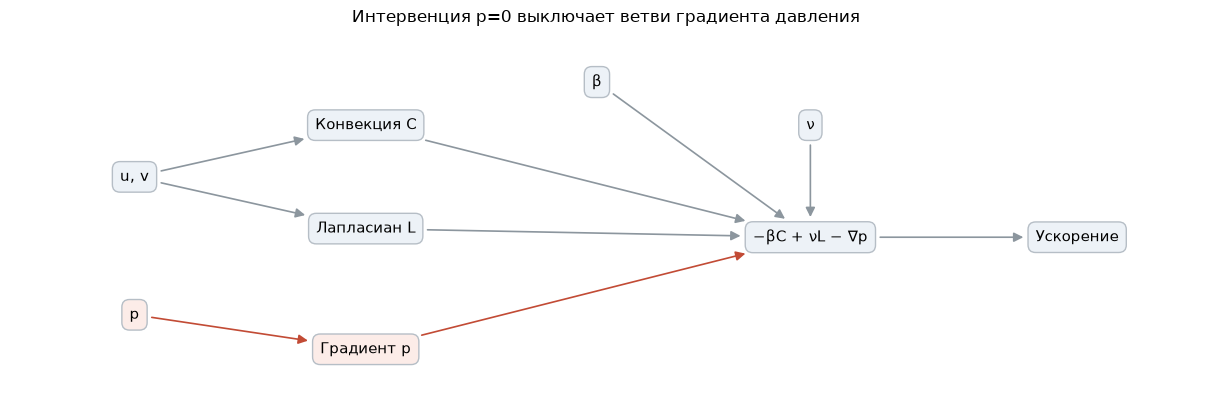

In [2]:
built = build_navier_stokes_2d()
pressure_edges = [(parent.id, node.id, node.op)
                  for node in built["tree"].nodes for parent in node.parents
                  if parent.id == built["p"].id]
print("Исходный граф:", len(built["tree"].nodes), "узлов")
print("Узел давления:", built["p"].id, "; его рёбра:", pressure_edges)
print("Узел вязкости:", built["params"]["ν"].id)
fig = plot_model_graph()
fig.savefig(OUTPUT/"model_graph.png", dpi=150)
plt.show()

## 2. Данные

Для проверки использую два примера.

**Вихрь Тейлора — Грина.** Это точное решение на $[0,2\pi)^2$:

$$
u=\sin x\cos y\,e^{-2\nu t},\qquad
v=-\cos x\sin y\,e^{-2\nu t},
$$

$$
p=\tfrac14(\cos 2x+\cos 2y)e^{-4\nu t}.
$$

Скорости, давление и производные считаю по этим формулам. К ускорениям добавляю независимый нормальный шум с σ, равным 1% среднеквадратичного значения точного ускорения. Это даёт небольшой разброс оценок параметров. Скорости и давление остаются точными. Использую сетку 32×32, 200 моментов времени с шагом 0,1 и seed=11.

**Течение за цилиндром.** Беру данные при Re=100 из открытых материалов Raissi, Perdikaris и Karniadakis: 200 кадров на сетке 100×50, поля u, v и p. Это результаты численного расчёта Nektar++, а не измерения в физическом эксперименте. Координаты и время читаю из файла.

В наборе PDEBench, который использовал Иван, давление не сохранено. Поэтому для выбранной интервенции понадобился другой набор данных для той же системы уравнений. В статье авторы использовали нейросеть PINN; в этой работе я беру только их данные и подбираю коэффициенты методом наименьших квадратов.

Производные внешних полей считаю центральными пятиузловыми разностями четвёртого порядка. По два узла с каждого края по пространству и времени исключаю. Перед этим убираю исходный кадр t=0; проверка ниже показывает его влияние на оценки. Первый оставшийся момент с вычисленными производными — t=0,3.

Противоположные стороны сетки не соединяю. Данные покрывают только часть следа за цилиндром, поэтому использую готовые поля и не запускаю новый расчёт течения на этой области.

Внешние поля (t,y,x): (200, 50, 100)
Первый момент после обработки: 0.30000000000000004
Погрешность синтетических ускорений σ: 8.304916557244841e-05


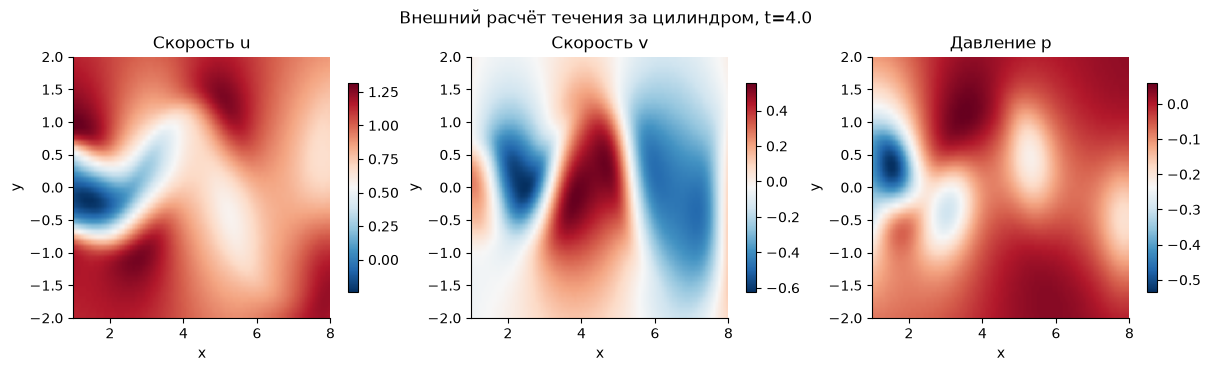

In [3]:
fields, _ = load_cylinder(ROOT/"data"/"processed")
SKIP_INITIAL_FRAMES = 1
external = momentum_from_fields(**fields, skip_initial_frames=SKIP_INITIAL_FRAMES)
synthetic, synthetic_fields = taylor_green()
print("Внешние поля (t,y,x):", fields["u"].shape)
print("Первый момент после обработки:", external.time[0])
print("Погрешность синтетических ускорений σ:", synthetic_fields["sigma_acceleration"])
fig = plot_fields(fields)
fig.savefig(OUTPUT/"cylinder_fields.png", dpi=150)
plt.show()

### Проверка начального кадра

При расчёте производной в t=0,2 в разностный шаблон попадает исходный кадр t=0. Оценка коэффициентов по первому окну при этом заметно отличается от остальных.

Ниже сравниваю первые два доступных момента и первое окно с кадром t=0,2 и без него. В основном расчёте исключаю исходный t=0 **до вычисления производных**, чтобы он не участвовал ни в одном шаблоне. Это предварительная обработка данных; зануление давления выполняется отдельно.

In [4]:
external_with_initial = momentum_from_fields(**fields)
initial_frame_check = []
for label, indices in (("Один кадр, t=0,2", np.array([0])),
                       ("Один кадр, t=0,3", np.array([1])),
                       ("Окно t=0,2…1,1", np.arange(10)),
                       ("То же окно без t=0,2", np.arange(1, 10))):
    theta = least_squares(*external_with_initial.design(indices))
    error = prediction_error(external_with_initial, indices, theta)
    initial_frame_check.append({"data": label, "theta": theta.tolist(), "fit_error": error})
rows = ["| Данные | β | ν | Ошибка подгонки ускорения |",
        "|---|---:|---:|---:|"]
for row in initial_frame_check:
    beta, nu = row["theta"]
    rows.append(f"| {row['data']} | {beta:.6f} | {nu:.6f} | {row['fit_error']:.3%} |")
display(Markdown("\n".join(rows)))


| Данные | β | ν | Ошибка подгонки ускорения |
|---|---:|---:|---:|
| Один кадр, t=0,2 | 0.939345 | 0.013013 | 4.486% |
| Один кадр, t=0,3 | 0.999964 | 0.010005 | 0.256% |
| Окно t=0,2…1,1 | 0.993818 | 0.010295 | 2.552% |
| То же окно без t=0,2 | 0.999965 | 0.010004 | 0.246% |

В момент t=0,2 ошибка заметно выше, и этот кадр смещает оценку по всему первому окну. Без него получаются значения около β=1 и ν=0,01. Причину отличия начального кадра я не установил. Дальше сравниваю результаты с ним и без него, чтобы проверить, влияет ли обработка на вывод о давлении.

## 3. Оценка распределения параметров

Обозначу конвекцию через $C=(uu_x+vu_y,uv_x+vv_y)$, лапласианы через $L=(\Delta u,\Delta v)$, а ускорения через $a=(u_t,v_t)$. На каждом временном блоке подбираю β и ν по минимуму суммы квадратов невязок:

$$
\widehat\theta=\arg\min_{\beta,\nu}\frac1N\left\|-\beta C+\nu L-\nabla p-a\right\|_2^2.
$$

Задача линейна по коэффициентам: $X=[-C,L]$, $y=a+\nabla p$. Для решения использую `numpy.linalg.lstsq` (SVD). Регуляризацию и ограничения на коэффициенты не добавляю. Если система теряет ранг, код останавливает расчёт.

Первые 120 доступных кадров делю на **12 блоков по 10 кадров**. На каждом получаю одну пару оценок β и ν. До и после зануления давления использую те же блоки. По полученным B=12 парам считаю среднее и выборочную ковариацию:

$$
\mu=\frac1B\sum_{b=1}^B\widehat\theta_b,\qquad
\Sigma=\frac1{B-1}\sum_{b=1}^B(\widehat\theta_b-\mu)(\widehat\theta_b-\mu)^T.
$$

Затем приближённо описываю оценки нормальным распределением $P=\mathcal N(\mu,\Sigma)$. Здесь Σ показывает разброс оценок между окнами. Это не ковариация среднего и не байесовское апостериорное распределение. Соседние окна могут быть зависимы, а 12 точек недостаточно, чтобы уверенно проверить нормальность. Поэтому эллипсы на графиках относятся к принятой нормальной аппроксимации; доверительными областями истинных параметров их считать нельзя.

После обучающих кадров пропускаю ещё четыре, а оставшиеся использую для проверки. Такой зазор нужен, чтобы временные шаблоны производных в обучении и проверке не пересекались. Ошибку на проверочных кадрах считаю с одной общей парой коэффициентов, подобранной по всем 120 обучающим кадрам. Проверочные данные в подбор коэффициентов, среднего и ковариации не входят.

## 4. Зануление давления и KL

Заменяю давление на **p=0 во всех точках**, оставляя исходные скорости и ускорения. Производные давления тоже становятся нулевыми. Так проверяю модель с выключенными ветвями давления на тех же наблюдениях. Новую физическую траекторию с нулевым давлением при этом не рассчитываю.

Кроме полного зануления, проверяю промежуточные значения: $p_\alpha=(1-\alpha)p$, где $\alpha\in\{0,0.25,0.5,0.75,1\}$. При α=0 давление исходное, при α=1 оно полностью убрано. Для каждого α заново подбираю коэффициенты на тех же временных блоках.

Распределения оценок до и после вмешательства обозначаю $P_0=\mathcal N(\mu_0,\Sigma_0)$ и $P_\alpha=\mathcal N(\mu_\alpha,\Sigma_\alpha)$. Сравниваю их по KL-дивергенции:

$$
D_{KL}(P_0\Vert P_\alpha)=\frac12\left[
\operatorname{tr}(\Sigma_\alpha^{-1}\Sigma_0)
+(\mu_\alpha-\mu_0)^T\Sigma_\alpha^{-1}(\mu_\alpha-\mu_0)
-2+\log\frac{\det\Sigma_\alpha}{\det\Sigma_0}\right].
$$

Основной показатель — KL(P₀‖Pα). Обратную KL тоже показываю на графике: в общем случае эти значения различаются. KL не является расстоянием в строгом смысле. Использую натуральный логарифм, поэтому единицы — наты. Перед вычислением проверяю положительную определённость ковариационных матриц.

Тейлор — Грин обучение: [0.0, 11.9] проверка: [12.4, 19.900000000000002]
Течение за цилиндром обучение: [0.30000000000000004, 12.200000000000001] проверка: [12.700000000000001, 19.700000000000003]


| Данные | α | β (общая оценка) | ν (общая оценка) | KL(P₀‖Pα) | Ошибка ускорения |
|---|---:|---:|---:|---:|---:|
| Тейлор — Грин | 0 | 1.000001 | 0.010000 | 0 | 1.142% |
| Тейлор — Грин | 0.25 | 0.750001 | 0.010000 | 6.694e+09 | 1.142% |
| Тейлор — Грин | 0.5 | 0.500001 | 0.010000 | 2.677e+10 | 1.142% |
| Тейлор — Грин | 0.75 | 0.250001 | 0.010000 | 6.024e+10 | 1.142% |
| Тейлор — Грин | 1 | 0.000001 | 0.010000 | 1.071e+11 | 1.142% |
| Течение за цилиндром | 0 | 0.999966 | 0.010005 | 0 | 0.261% |
| Течение за цилиндром | 0.25 | 0.949499 | 0.008908 | 249.2 | 11.321% |
| Течение за цилиндром | 0.5 | 0.899033 | 0.007810 | 251.1 | 22.638% |
| Течение за цилиндром | 0.75 | 0.848566 | 0.006713 | 252.1 | 33.955% |
| Течение за цилиндром | 1 | 0.798099 | 0.005616 | 252.8 | 45.273% |

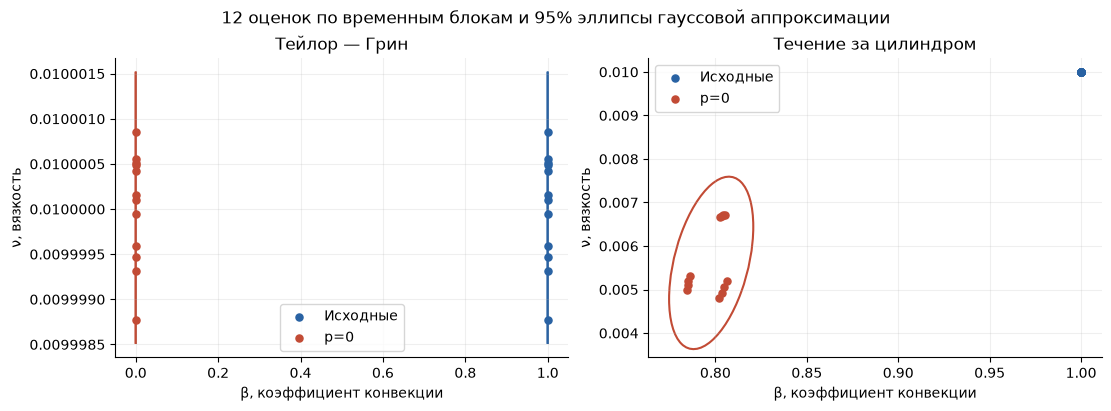

In [5]:
results = {"Тейлор — Грин": run_experiment(synthetic),
           "Течение за цилиндром": run_experiment(external)}
for name, result in results.items():
    print(name, "обучение:", result["train_time"], "проверка:", result["test_time"])
rows = ["| Данные | α | β (общая оценка) | ν (общая оценка) | KL(P₀‖Pα) | Ошибка ускорения |",
        "|---|---:|---:|---:|---:|---:|"]
for name, result in results.items():
    for row in result["rows"]:
        beta, nu = row["global_theta"]
        rows.append(f"| {name} | {row['alpha']:g} | {beta:.6f} | {nu:.6f} | {row['kl']:.4g} | {row['test_error']:.3%} |")
display(Markdown("\n".join(rows)))
fig = plot_distributions(results)
fig.savefig(OUTPUT/"parameter_distributions.png", dpi=150)
plt.show()

### Влияние обработки начала записи

Ниже сравниваю расчёт по всем исходным кадрам и расчёт с исключением t=0. В обоих случаях беру 12 окон по 10 кадров. Во втором случае окна и начало проверки сдвигаются на один шаг времени — 0,1.

In [6]:
original_preprocessing = run_experiment(external_with_initial)
preprocessing_comparison = []
rows = ["| Обработка | std(β) | cond(Σ₀) | KL(P₀‖P₁) | Ошибка до p=0 | Ошибка после p=0 |",
        "|---|---:|---:|---:|---:|---:|"]
for label, result in (("Все исходные кадры", original_preprocessing),
                      ("Без исходного t=0", results["Течение за цилиндром"])):
    first, last = result["rows"][0], result["rows"][-1]
    covariance = np.asarray(first["covariance"])
    row = {"preprocessing": label, "std_beta": float(np.sqrt(covariance[0, 0])),
           "covariance_condition": float(np.linalg.cond(covariance)),
           "kl": last["kl"], "baseline_error": first["test_error"],
           "intervention_error": last["test_error"], "decision": result["decision"],
           "train_time": result["train_time"], "test_time": result["test_time"]}
    preprocessing_comparison.append(row)
    rows.append(f"| {label} | {row['std_beta']:.3g} | {row['covariance_condition']:.3g} | "
                f"{row['kl']:.2f} | {row['baseline_error']:.3%} | {row['intervention_error']:.3%} |")
display(Markdown("\n".join(rows)))


| Обработка | std(β) | cond(Σ₀) | KL(P₀‖P₁) | Ошибка до p=0 | Ошибка после p=0 |
|---|---:|---:|---:|---:|---:|
| Все исходные кадры | 0.00177 | 9.36e+06 | 249.97 | 0.268% | 45.252% |
| Без исходного t=0 | 5.22e-06 | 89.6 | 252.79 | 0.261% | 45.273% |

Исключение начального кадра заметно уменьшает разброс оценок β и число обусловленности исходной ковариации. При этом KL и ошибка после зануления давления меняются мало. Вывод в обоих случаях одинаковый: давление оставляю. Дальше для внешних данных использую расчёт без исходного t=0.

На синтетическом примере после зануления давления β меняется с 1 почти до 0, а ν остаётся около 0,01. В решении Тейлора — Грина конвекция уравновешивается градиентом давления. Если убрать оба слагаемых, ускорение сохранится. Поэтому по одной ошибке на этой траектории нельзя отличить полную модель от модели с p=0 и β=0. По выбранному критерию устойчивости коэффициентов давление нужно оставить.

В течении за цилиндром полностью компенсировать давление подбором коэффициентов не получается: меняются β и ν, а ошибка растёт. Синие точки на этом графике почти сливаются из-за малого исходного разброса, хотя показаны все 12 оценок.

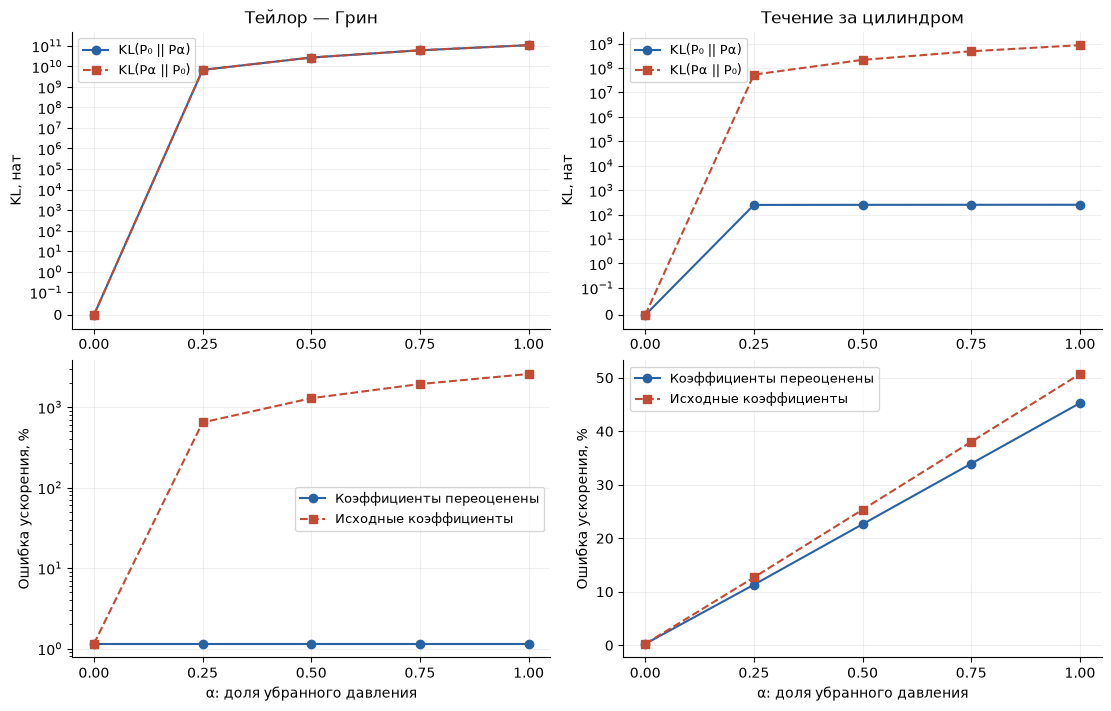

In [7]:
fig = plot_sensitivity(results)
fig.savefig(OUTPUT/"intervention_sensitivity.png", dpi=150)
plt.show()

На нижних графиках показана относительная ошибка ускорений на проверочных кадрах:

$$
\varepsilon=\frac{\|\widehat a-a\|_2}{\|a\|_2}.
$$

Сравниваю ускорения из уравнения с ускорениями, вычисленными по готовым кадрам. Сплошная линия — результат с заново подобранными β и ν, пунктир — с исходными коэффициентами. В обоих случаях наблюдаемые ускорения остаются прежними.

На синтетике KL очень большая: исходный разброс β мал, а после зануления его значение сдвигается почти на единицу. Поэтому абсолютные значения KL разных наборов нельзя напрямую сравнивать как «важность давления». При изменении α меняются и среднее, и ковариация, так что монотонный рост KL не гарантирован.

## 5. Риманова геометрия

Для сравнения изменений параметров использую метрику $g=\Sigma^{-1}$. Длина изменения $h$ в этой метрике равна $\sqrt{h^T\Sigma^{-1}h}$. Сдвиг в направлении, где оценки обычно мало разбросаны, получает больший вес. Если Σ фиксирована, метрика постоянна и пространство параметров остаётся плоским.

Отдельно рассматриваю пространство положительно определённых ковариационных матриц SPD(2). Для него беру аффинно-инвариантную метрику:

$$
\langle H,K\rangle_\Sigma=\operatorname{tr}(\Sigma^{-1}H\Sigma^{-1}K).
$$

Геодезическая между ковариациями A и B имеет вид:

$$
\Sigma(s)=A^{1/2}(A^{-1/2}BA^{-1/2})^sA^{1/2},\quad 0\le s\le1,
$$

Расстояние между ними: $d(A,B)=\|\log(A^{-1/2}BA^{-1/2})\|_F$. Здесь сравниваются только ковариации, а KL из предыдущего раздела учитывает ещё и изменение среднего. Параметр s задаёт положение на геодезической и не связан с физическим временем.

На левом рисунке центры эллипсов совмещены с нулём, а оси измеряются в исходных стандартных отклонениях. Это позволяет сравнить форму и размер эллипсов. Справа показано расстояние до ковариаций, полученных при разных α. Эти ковариации не обязаны лежать на геодезической между крайними точками.

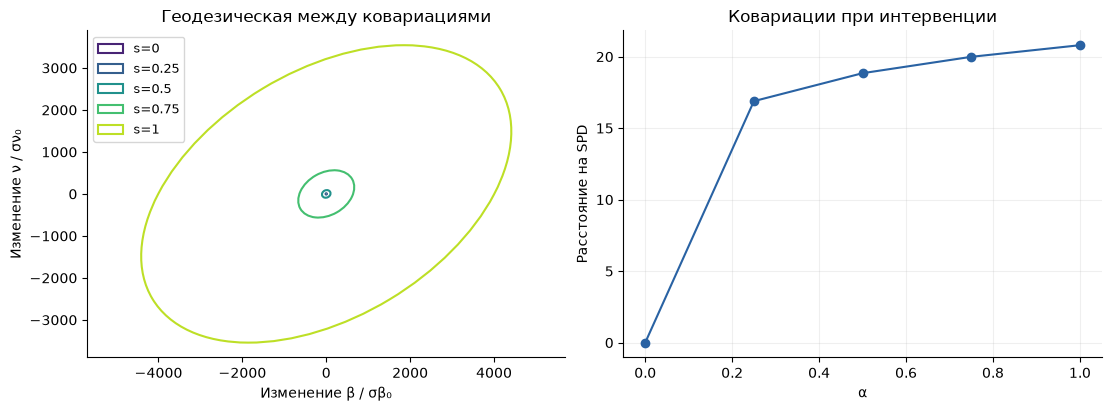

In [8]:
fig = plot_covariance_geometry(results["Течение за цилиндром"])
fig.savefig(OUTPUT/"covariance_geometry.png", dpi=150)
plt.show()

## 6. Проверка и вывод

Для контрольной проверки заменяю p на p+3. При добавлении пространственно постоянной величины градиент давления не меняется, поэтому оценки коэффициентов должны остаться теми же, а KL должна быть нулевой.

В этой работе рассматриваю удаление ветви, только если одновременно выполнены условия: ошибка исходной модели не больше 5%, KL не больше 0,1, относительная ошибка после вмешательства выросла не более чем на 0,01, а общие оценки β и ν положительны. Порог 0,01 соответствует одному процентному пункту.

Это выбранное для опыта правило, а не статистический тест. Даже если все условия выполнены, они дают основание проверить упрощённую модель дальше, но не доказывают отсутствие физического влияния переменной.

In [9]:
shifted_fields = dict(fields, p=fields["p"].astype(float)+3)
shifted = momentum_from_fields(**shifted_fields, skip_initial_frames=SKIP_INITIAL_FRAMES)
blocks = [np.arange(i*10,(i+1)*10) for i in range(12)]
original_gaussian = estimate_gaussian(results["Течение за цилиндром"]["samples"][0])
shift_gaussian = estimate_gaussian(fit_blocks(shifted, blocks))
control_kl = gaussian_kl(original_gaussian, shift_gaussian)
print(f"KL для p -> p+3: {control_kl:.3e}")
assert control_kl < 1e-8
for name, result in results.items():
    row = result["rows"][-1]
    print(name, result["decision"], "KL =", row["kl"])
output = {"variant":[2,1,2], "pressure_edges":pressure_edges,
          "constant_pressure_shift_kl":control_kl,
          "preprocessing": {"skip_initial_frames": SKIP_INITIAL_FRAMES,
                            "excluded_raw_times": fields["time"][:SKIP_INITIAL_FRAMES].tolist(),
                            "first_derivative_time": float(external.time[0])},
          "initial_frame_check": initial_frame_check,
          "preprocessing_comparison": preprocessing_comparison,
          "results":{name:json_result(result) for name,result in results.items()}}
(OUTPUT/"metrics.json").write_text(json.dumps(output,ensure_ascii=False,indent=2)+"\n")

KL для p -> p+3: 0.000e+00
Тейлор — Грин retain_pressure_branch KL = 107096556650.98822
Течение за цилиндром retain_pressure_branch KL = 252.79281422653037


**По результатам оставляю давление и обе его связи с пространственными производными.**

На синтетическом примере ошибка почти не меняется, но β сдвигается с 1 почти до 0. Поэтому удаление давления не проходит выбранный критерий устойчивости параметров. На внешних данных ошибка после повторного подбора коэффициентов растёт с 0,26% до 45,27%, а KL(P₀‖P₁) составляет около 253 нат. Исключение начального кадра этот вывод не меняет.

Вывод относится к этим двум наборам данных и выбранным коэффициентам модели. При вмешательстве скорости и ускорения оставались исходными, поэтому результат описывает изменение вычислительной модели и сам по себе не доказывает физическую причинность.

Внешний набор Nektar++ получен численно. Нужно уточнить у преподавателя, подходит ли он под пункт «реальные данные».

## Источники

- Задание «Лабораторная работа №2», вариант 2–1–2, распределение от 20.10.2026.
- [Иван / papayiv: исходная модель и граф](https://github.com/papayiv/NavieStocks_project/tree/66eb7bc73cd802a3249c058ad69fc59a95fbd807).
- [Raissi, Perdikaris, Karniadakis (2019). Physics-informed neural networks](https://doi.org/10.1016/j.jcp.2018.10.045), [описание примера Навье — Стокса авторами](https://maziarraissi.github.io/PINNs/), [исходные данные](https://github.com/maziarraissi/PINNs/blob/932f50a2d8ef4e80d1456bbae6887a73ff5166ef/main/Data/cylinder_nektar_wake.mat).
- [Rudy et al. (2017). Data-driven discovery of partial differential equations](https://doi.org/10.1126/sciadv.1602614): оценка коэффициентов дифференциального уравнения по наблюдаемым полям.
- [Pennec, Fillard, Ayache (2006). A Riemannian Framework for Tensor Computing](https://doi.org/10.1007/s11263-005-3222-z): аффинно-инвариантная геометрия положительно определённых матриц.
- [Zhang et al. On the Properties of Kullback-Leibler Divergence Between Multivariate Gaussian Distributions](https://arxiv.org/abs/2102.05485): формула и направленность KL для нормальных распределений.

Код анализа — в `src/navier_lab/`, проверки — в `tests/test_navier_lab.py`. Помощь ИИ описана в `ai/`.